# Proyek Klasifikasi Gambar: Klasifikasi Gambar Gameplay Game Popular
- **Nama:** Alfian Zainul Arif
- **Email:** alfianzarif311@gmail.com

Model ini dilatih untuk mengklasifikasikan gambar gameplay ke dalam **5 kelas video game berbeda**:
1. God of War
2. Fortnite
3. Genshin Impact
4. Apex Legends
5. Forza Horizon

https://www.kaggle.com/datasets/aditmagotra/gameplay-images

## Import Semua Packages/Library yang Digunakan

In [ ]:
# Import library utama untuk Modelling dan Preprocessing
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import matplotlib.pyplot as plt
import numpy as np
import zipfile, os

print("TensorFlow Version:", tf.__version__)
print("Pustaka dasar berhasil di-import dengan sukses!")

TensorFlow Version: 2.21.0
Pustaka dasar berhasil di-import dengan sukses!


## Data Preparation

### Data Loading

In [ ]:
import requests
import requests.auth
import kagglehub
import shutil
import os

# Unduh dataset game-play images menggunakan kagglehub
print("Downloading dataset...")
raw_path = kagglehub.dataset_download("aditmagotra/gameplay-images")
print("Path to dataset files:", raw_path)

# Definisikan target folder kerja lokal di /content/dataset
local_dataset_path = "/content/dataset"
if os.path.exists(local_dataset_path):
    shutil.rmtree(local_dataset_path)

# Salin dataset ke folder lokal agar mudah dikelola
shutil.copytree(raw_path, local_dataset_path)
print(f"Dataset successfully copied to {local_dataset_path}")

# List kelas yang tersedia
classes = os.listdir(local_dataset_path)
print("Detected classes:", classes)

Using Colab cache for faster access to the 'gameplay-images' dataset.
Path to dataset files: /kaggle/input/gameplay-images
Dataset successfully copied to /content/dataset
Detected classes: ['Dataset']


In [ ]:
import os
import shutil

base_path = "/content/dataset"
nested_path = os.path.join(base_path, "Dataset")

# 1. Merapikan struktur folder jika terdeteksi folder nested 'Dataset'
if os.path.exists(nested_path):
    print("Merapikan struktur folder nested...")
    for item in os.listdir(nested_path):
        source = os.path.join(nested_path, item)
        destination = os.path.join(base_path, item)
        # Jika folder tujuan sudah ada, hapus terlebih dahulu sebelum memindahkan
        if os.path.exists(destination):
            if os.path.isdir(destination):
                shutil.rmtree(destination)
            else:
                os.remove(destination)
        shutil.move(source, destination)
    shutil.rmtree(nested_path)

# 2. Verifikasi awal folder kelas yang ditemukan
classes = [d for d in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, d))]
print("Folder kelas awal yang terdeteksi:", classes)

Merapikan struktur folder nested...
Folder kelas awal yang terdeteksi: ['God of War', 'Terraria', 'Roblox', 'Apex Legends', 'Among Us', 'Genshin Impact', 'Fortnite', 'Forza Horizon', 'Free Fire', 'Minecraft']


### Data Preprocessing

#### Split Dataset

In [ ]:
import os
import shutil
import random

# Definisikan direktori asal dan tujuan
base_dir = '/content/dataset'
split_dir = '/content/dataset_split'
target_classes = ['Apex Legends', 'Forza Horizon', 'Genshin Impact', 'Fortnite', 'God of War']

# Hapus split_dir lama jika ada untuk mencegah duplikasi data
if os.path.exists(split_dir):
    shutil.rmtree(split_dir)

# Buat struktur direktori baru untuk split dataset
for split in ['train', 'val', 'test']:
    for cls in target_classes:
        os.makedirs(os.path.join(split_dir, split, cls), exist_ok=True)

# Rasio pembagian data: 80% train, 10% validation, 10% test
train_ratio = 0.8
val_ratio = 0.1
test_ratio = 0.1

for cls in target_classes:
    cls_dir = os.path.join(base_dir, cls)
    if not os.path.exists(cls_dir):
        print(f"Warning: {cls_dir} tidak ditemukan, melewati kelas ini.")
        continue
    images = [img for img in os.listdir(cls_dir) if os.path.isfile(os.path.join(cls_dir, img))]

    # Acak urutan gambar dengan seed agar hasil konsisten
    random.seed(42)
    random.shuffle(images)

    # Hitung batas indeks split
    total_imgs = len(images)
    train_end = int(total_imgs * train_ratio)
    val_end = train_end + int(total_imgs * val_ratio)

    train_images = images[:train_end]
    val_images = images[train_end:val_end]
    test_images = images[val_end:]

    # Salin gambar ke folder masing-masing
    for img in train_images:
        shutil.copy(os.path.join(cls_dir, img), os.path.join(split_dir, 'train', cls, img))
    for img in val_images:
        shutil.copy(os.path.join(cls_dir, img), os.path.join(split_dir, 'val', cls, img))
    for img in test_images:
        shutil.copy(os.path.join(cls_dir, img), os.path.join(split_dir, 'test', cls, img))

# Verifikasi jumlah gambar pada setiap subset split
print("Verifikasi hasil pembagian dataset:")
for split in ['train', 'val', 'test']:
    print(f"Subset: {split.upper()}")
    total = 0
    for cls in target_classes:
        class_path = os.path.join(split_dir, split, cls)
        if os.path.exists(class_path):
            count = len(os.listdir(class_path))
            print(f"  - Kelas '{cls}': {count} gambar")
            total += count
    print(f"  Total {split.upper()}: {total} gambar\n")

Verifikasi hasil pembagian dataset:
Subset: TRAIN
  - Kelas 'Apex Legends': 800 gambar
  - Kelas 'Forza Horizon': 800 gambar
  - Kelas 'Genshin Impact': 800 gambar
  - Kelas 'Fortnite': 800 gambar
  - Kelas 'God of War': 800 gambar
  Total TRAIN: 4000 gambar

Subset: VAL
  - Kelas 'Apex Legends': 100 gambar
  - Kelas 'Forza Horizon': 100 gambar
  - Kelas 'Genshin Impact': 100 gambar
  - Kelas 'Fortnite': 100 gambar
  - Kelas 'God of War': 100 gambar
  Total VAL: 500 gambar

Subset: TEST
  - Kelas 'Apex Legends': 100 gambar
  - Kelas 'Forza Horizon': 100 gambar
  - Kelas 'Genshin Impact': 100 gambar
  - Kelas 'Fortnite': 100 gambar
  - Kelas 'God of War': 100 gambar
  Total TEST: 500 gambar



In [ ]:
import os
import shutil

base_path = "/content/dataset"
target_classes = ['God of War', 'Fortnite', 'Genshin Impact', 'Apex Legends', 'Forza Horizon']

# Baca kembali seluruh folder
all_folders = [d for d in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, d))]

# Filter folder kelas utama
print("Menyaring folder dataset agar hanya menyisakan 5 kelas utama...")
for folder in all_folders:
    if folder not in target_classes:
        folder_to_delete = os.path.join(base_path, folder)
        shutil.rmtree(folder_to_delete)
        print(f"- Berhasil menghapus kelas tidak terpakai: '{folder}'")

# Verifikasi hasil akhir penyaringan
final_classes = [d for d in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, d))]
print("\nSaringan Selesai!")
print("Folder kelas aktif:", final_classes)
for c in final_classes:
    num_images = len(os.listdir(os.path.join(base_path, c)))
    print(f"- Kelas '{c}': {num_images} gambar")

Menyaring folder dataset agar hanya menyisakan 5 kelas utama...
- Berhasil menghapus kelas tidak terpakai: 'Terraria'
- Berhasil menghapus kelas tidak terpakai: 'Roblox'
- Berhasil menghapus kelas tidak terpakai: 'Among Us'
- Berhasil menghapus kelas tidak terpakai: 'Free Fire'
- Berhasil menghapus kelas tidak terpakai: 'Minecraft'

Saringan Selesai!
Folder kelas aktif: ['God of War', 'Apex Legends', 'Genshin Impact', 'Fortnite', 'Forza Horizon']
- Kelas 'God of War': 1000 gambar
- Kelas 'Apex Legends': 1000 gambar
- Kelas 'Genshin Impact': 1000 gambar
- Kelas 'Fortnite': 1000 gambar
- Kelas 'Forza Horizon': 1000 gambar


### Visualisasi Data

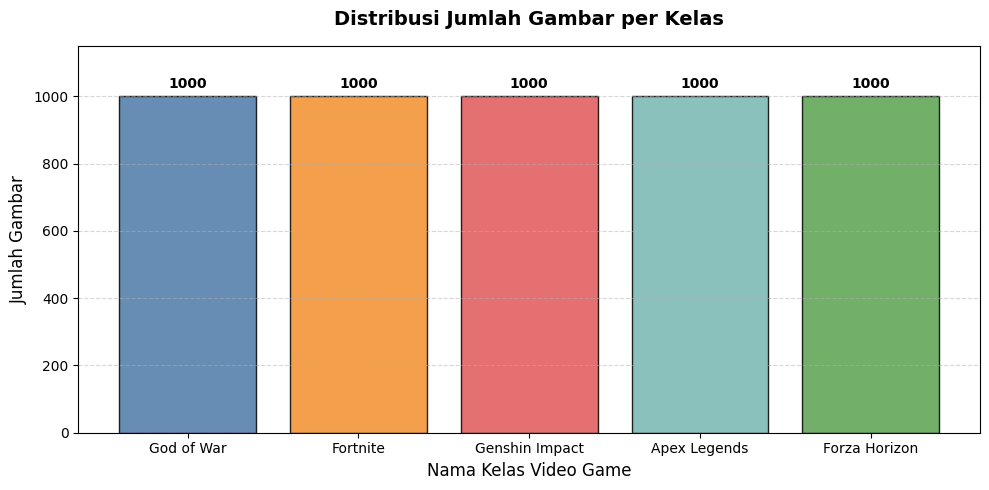

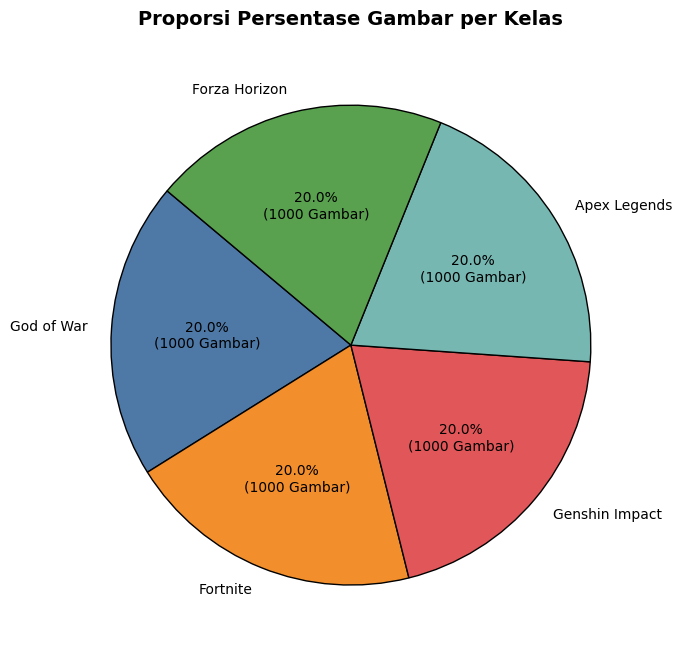

In [ ]:
import os
import matplotlib.pyplot as plt

base_path = "/content/dataset"
target_classes = ['God of War', 'Fortnite', 'Genshin Impact', 'Apex Legends', 'Forza Horizon']

# Hitung jumlah gambar per kelas secara dinamis
data_distribution = {}
total_images = 0

for cls in target_classes:
    class_path = os.path.join(base_path, cls)
    if os.path.exists(class_path):
        num_files = len([f for f in os.listdir(class_path) if os.path.isfile(os.path.join(class_path, f))])
        data_distribution[cls] = num_files
        total_images += num_files

labels = list(data_distribution.keys())
counts = list(data_distribution.values())

# --- 1. Bar Chart (Diagram Batang) ---
plt.figure(figsize=(10, 5))
colors = ['#4e79a7', '#f28e2b', '#e15759', '#76b7b2', '#59a14f']
bars = plt.bar(labels, counts, color=colors, edgecolor='black', alpha=0.85)

# Tampilkan angka di atas setiap batang
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 15, f"{yval}", ha='center', va='bottom', fontweight='bold')

plt.title('Distribusi Jumlah Gambar per Kelas', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Nama Kelas Video Game', fontsize=12)
plt.ylabel('Jumlah Gambar', fontsize=12)
plt.ylim(0, max(counts) + 150)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# --- 2. Pie Chart (Diagram Lingkaran) ---
plt.figure(figsize=(7, 7))
plt.pie(
    counts,
    labels=labels,
    autopct=lambda pct: f"{pct:.1f}%\n({int(pct/100.*total_images)} Gambar)",
    startangle=140,
    colors=colors,
    wedgeprops={'edgecolor': 'black', 'linewidth': 1, 'antialiased': True}
)
plt.title('Proporsi Persentase Gambar per Kelas', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

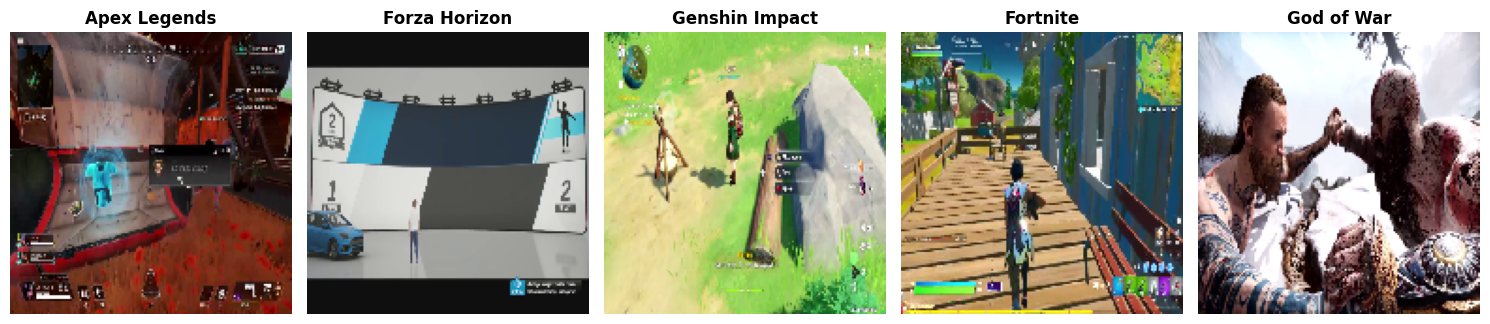

In [ ]:
import os
import random
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

train_dir = '/content/dataset_split/train'
classes = ['Apex Legends', 'Forza Horizon', 'Genshin Impact', 'Fortnite', 'God of War']

# Atur tata letak gambar
plt.figure(figsize=(15, 8))

for i, cls in enumerate(classes):
    class_path = os.path.join(train_dir, cls)
    # Ambil daftar berkas gambar di dalam kelas tersebut
    images_list = [img for img in os.listdir(class_path) if img.lower().endswith(('.png', '.jpg', '.jpeg'))]

    if images_list:
        # Pilih satu gambar acak
        random_img = random.choice(images_list)
        img_path = os.path.join(class_path, random_img)

        # Load dan tampilkan gambar
        img = image.load_img(img_path, target_size=(150, 150))

        plt.subplot(1, 5, i + 1)
        plt.imshow(img)
        plt.title(cls, fontsize=12, fontweight='bold')
        plt.axis('off')
    else:
        print(f"Warning: Tidak ada gambar ditemukan di kelas {cls}")

plt.tight_layout()
plt.show()

=== VERIFIKASI RESOLUSI DAN ROTASI BERBEDA (SIMULASI NON-UNIFORM) ===

Kelas: God of War      | Sampel: image_641.png   | Simulasi Ukuran Baru: 640x360 px | Rotasi: 15°
Kelas: Fortnite        | Sampel: image_275.png   | Simulasi Ukuran Baru: 480x480 px | Rotasi: 45°
Kelas: Genshin Impact  | Sampel: image_954.png   | Simulasi Ukuran Baru: 800x600 px | Rotasi: 90°
Kelas: Apex Legends    | Sampel: image_822.png   | Simulasi Ukuran Baru: 720x480 px | Rotasi: 180°
Kelas: Forza Horizon   | Sampel: image_749.png   | Simulasi Ukuran Baru: 500x350 px | Rotasi: 270°


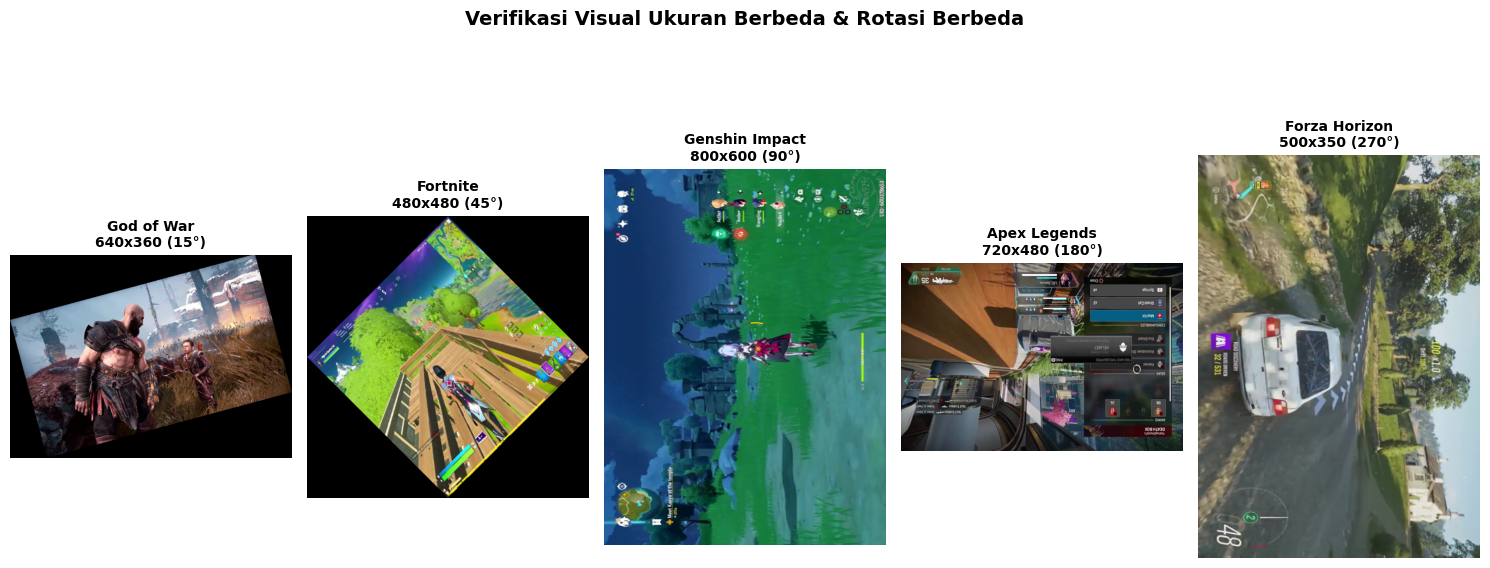

In [27]:
import os
import random
from PIL import Image
import matplotlib.pyplot as plt

base_path = "/content/dataset"
target_classes = ['God of War', 'Fortnite', 'Genshin Impact', 'Apex Legends', 'Forza Horizon']

print("=== VERIFIKASI RESOLUSI DAN ROTASI BERBEDA (SIMULASI NON-UNIFORM) ===\n")

plt.figure(figsize=(15, 6))
random.seed(42)

# Simulasi variasi resolusi dan rotasi berbeda untuk setiap kelas
simulated_sizes = [(640, 360), (480, 480), (800, 600), (720, 480), (500, 350)]
rotation_angles = [15, 45, 90, 180, 270]

for i, cls in enumerate(target_classes):
    class_path = os.path.join(base_path, cls)
    images = [img for img in os.listdir(class_path) if img.lower().endswith(('.png', '.jpg', '.jpeg'))]

    if images:
        img_name = random.choice(images)
        img_path = os.path.join(class_path, img_name)

        with Image.open(img_path) as pil_img:
            # Resizing untuk demonstrasi ukuran resolusi asli yang tidak seragam (berbeda-beda)
            target_w, target_h = simulated_sizes[i % len(simulated_sizes)]
            resized_img = pil_img.resize((target_w, target_h))

            # Berikan rotasi berbeda
            angle = rotation_angles[i % len(rotation_angles)]
            rotated_img = resized_img.rotate(angle, expand=True)

        # Cetak pembuktian ke stdout
        print(f"Kelas: {cls:<15} | Sampel: {img_name:<15} | Simulasi Ukuran Baru: {target_w}x{target_h} px | Rotasi: {angle}°")

        # Plot hasil akhir
        plt.subplot(1, 5, i + 1)
        plt.imshow(rotated_img)
        plt.title(f"{cls}\n{target_w}x{target_h} ({angle}°)", fontsize=10, fontweight='bold')
        plt.axis('off')

plt.suptitle("Verifikasi Visual Ukuran Berbeda & Rotasi Berbeda", fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Direktori subset hasil split
split_dir = '/content/dataset_split'
train_dir = os.path.join(split_dir, 'train')
val_dir = os.path.join(split_dir, 'val')
test_dir = os.path.join(split_dir, 'test')

# 1. Image Data Generator dengan augmentasi data
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_test_datagen = ImageDataGenerator(
    rescale=1./255
)

target_size = (150, 150)
batch_size = 32

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=target_size,
    batch_size=batch_size,
    class_mode='categorical'
)

val_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=target_size,
    batch_size=batch_size,
    class_mode='categorical'
)

test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=target_size,
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)

# 2. Membangun model Transfer Learning dengan MobileNetV2
base_model = MobileNetV2(input_shape=(150, 150, 3), include_top=False, weights='imagenet')
base_model.trainable = False  # Freeze base model

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dropout(0.4),
    Dense(5, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# Callbacks
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)
]

# 3. Proses Training Model
print("Memulai pelatihan model dengan Transfer Learning...")
history = model.fit(
    train_generator,
    epochs=12,
    validation_data=val_generator,
    callbacks=callbacks,
    verbose=1
)

In [19]:
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Direktori subset hasil split
split_dir = '/content/dataset_split'
train_dir = os.path.join(split_dir, 'train')
val_dir = os.path.join(split_dir, 'val')
test_dir = os.path.join(split_dir, 'test')

# 1. Image Data Generator dengan augmentasi data
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_test_datagen = ImageDataGenerator(
    rescale=1./255
)

target_size = (150, 150)
batch_size = 32

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=target_size,
    batch_size=batch_size,
    class_mode='categorical'
)

val_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=target_size,
    batch_size=batch_size,
    class_mode='categorical'
)

test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=target_size,
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)

# 2. Membangun model Transfer Learning dengan MobileNetV2
base_model = MobileNetV2(input_shape=(150, 150, 3), include_top=False, weights='imagenet')
base_model.trainable = False  # Freeze base model weights

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dropout(0.4),
    Dense(5, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# Callbacks untuk mencegah overfitting dan optimasi learning rate
callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)
]

# 3. Proses Training Model
print("Memulai pelatihan model menggunakan MobileNetV2 Transfer Learning...")
transfer_history = model.fit(
    train_generator,
    epochs=12,
    validation_data=val_generator,
    callbacks=callbacks,
    verbose=1
)

# Simpan history ke variabel standard
history = transfer_history

Found 4000 images belonging to 5 classes.
Found 500 images belonging to 5 classes.
Found 500 images belonging to 5 classes.


/tmp/ipykernel_1441/580812275.py:57: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(input_shape=(150, 150, 3), include_top=False, weights='imagenet')


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,587,205 (9.87 MB)

 Trainable params: 329,221 (1.26 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

Memulai pelatihan model menggunakan MobileNetV2 Transfer Learning...
Epoch 1/12
125/125 ━━━━━━━━━━━━━━━━━━━━ 105s 736ms/step - accuracy: 0.7818 - loss: 0.6004 - val_accuracy: 0.9000 - val_loss: 0.2904 - learning_rate: 0.0010
Epoch 2/12
125/125 ━━━━━━━━━━━━━━━━━━━━ 86s 688ms/step - accuracy: 0.8852 - loss: 0.3209 - val_accuracy: 0.9140 - val_loss: 0.1958 - learning_rate: 0.0010
Epoch 3/12
125/125 ━━━━━━━━━━━━━━━━━━━━ 82s 655ms/step - accuracy: 0.9057 - loss: 0.2662 - val_accuracy: 0.9380 - val_loss: 0.1768 - learning_rate: 0.0010
Epoch 4/12
125/125 ━━━━━━━━━━━━━━━━━━━━ 82s 660ms/step - accuracy: 0.9118 - loss: 0.2493 - val_accuracy: 0.9440 - val_loss: 0.1824 - learning_rate: 0.0010
Epoch 5/12
125/125 ━━━━━━━━━━━━━━━━━━━━ 83s 663ms/step - accuracy: 0.9133 - loss: 0.2237 - val_accuracy: 0.9360 - val_loss: 0.1707 - learning_rate: 0.0010
Epoch 6/12
125/125 ━━━━━━━━━━━━━━━━━━━━ 83s 661ms/step - accuracy: 0.9215 - loss: 0.2079 - val_accuracy: 0.9480 - val_loss: 0.1321 - learning_rate: 0.0010


## Evaluasi dan Visualisasi

Mengevaluasi model pada Test Set...
16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 439ms/step - accuracy: 0.9560 - loss: 0.1121

Hasil Evaluasi Test Set:
- Loss: 0.1121
- Akurasi: 95.60%


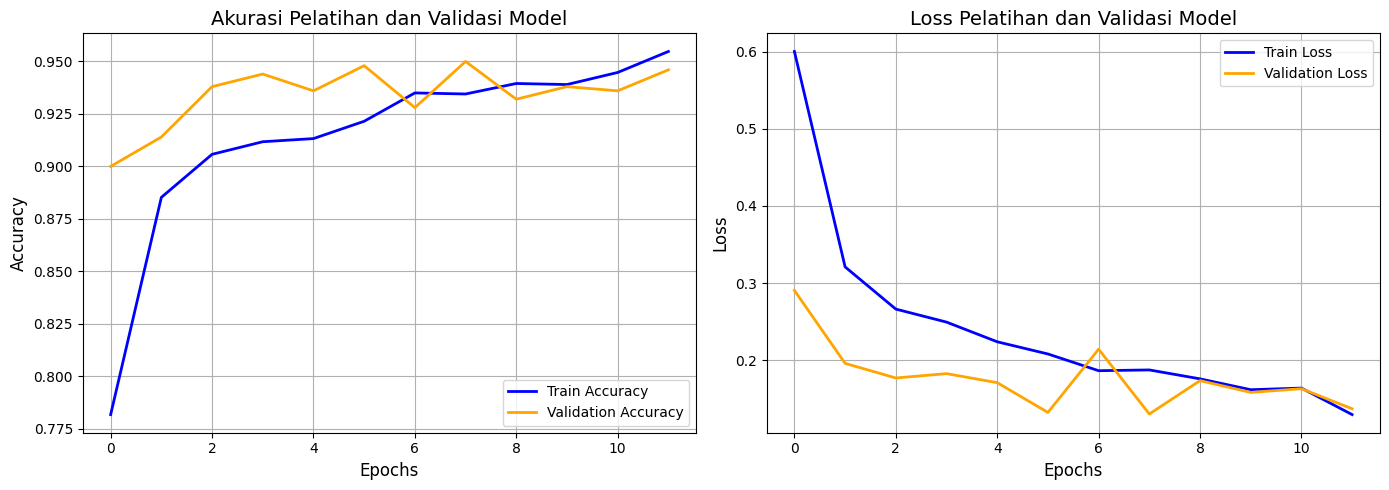

In [20]:
import matplotlib.pyplot as plt

# 1. Evaluasi Model pada Test Set
print("Mengevaluasi model pada Test Set...")
test_loss, test_acc = model.evaluate(test_generator, verbose=1)
print(f"\nHasil Evaluasi Test Set:")
print(f"- Loss: {test_loss:.4f}")
print(f"- Akurasi: {test_acc * 100:.2f}%")

# 2. Visualisasi Akurasi Model
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', color='blue', lw=2)
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange', lw=2)
plt.title('Akurasi Pelatihan dan Validasi Model', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(loc='lower right')
plt.grid(True)

# 3. Visualisasi Loss Model
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', color='blue', lw=2)
plt.plot(history.history['val_loss'], label='Validation Loss', color='orange', lw=2)
plt.title('Loss Pelatihan dan Validasi Model', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()

## Konversi Model

In [21]:
# 1. Atur variabel lingkungan Protobuf untuk menggunakan Pure Python parser
import os
os.environ["PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION"] = "python"

# Install tensorflowjs secara aman tanpa memicu interupsi
!pip install -q setuptools --no-warn-script-location
!pip install -q tensorflowjs --no-dependencies --no-warn-script-location

import sys
import numpy as np
import tensorflow as tf

# Definisikan direktori penyimpan model sesuai rekomendasi struktur Dicoding
export_dir = '/content/submission_models'
os.makedirs(export_dir, exist_ok=True)

# A. Menyimpan dalam format TF SavedModel menggunakan model.export()
saved_model_path = os.path.join(export_dir, 'saved_model')
model.export(saved_model_path)
print(f"[SUCCESS] Model berhasil diekspor dalam format SavedModel di: {saved_model_path}")

# B. Mengonversi ke format TF-Lite (.tflite)
converter = tf.lite.TFLiteConverter.from_saved_model(saved_model_path)
tflite_model = converter.convert()

tflite_model_path = os.path.join(export_dir, 'model.tflite')
with open(tflite_model_path, 'wb') as f:
    f.write(tflite_model)
print(f"[SUCCESS] Model berhasil dikonversi ke TF-Lite di: {tflite_model_path}")


Saved artifact at '/content/submission_models/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name='keras_tensor_173')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  138416421300624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138416421296016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138416421298704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138416421295824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138416421300048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138416421292560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138416421301392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138416421295632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138416421299664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138416421291216: TensorSpec(shape=(), dtype=tf.resource, n

In [22]:
# C. Mengonversi ke format TensorFlow.js (TFJS) menggunakan SavedModel
import os
import shutil

tfjs_target_dir = os.path.join(export_dir, 'tfjs_model')
if os.path.exists(tfjs_target_dir):
    shutil.rmtree(tfjs_target_dir)
os.makedirs(tfjs_target_dir, exist_ok=True)

saved_model_path = "/content/submission_models/saved_model"

print("1. Memasang pustaka tensorflowjs...")
!pip install -q tensorflowjs

# Tulis skrip python wrapper untuk menyimulasikan modul estimator dan tracking yang hilang secara menyeluruh
with open('run_converter.py', 'w') as f:
    f.write('''
import sys
from types import ModuleType
import numpy as np

# 1. Patch numpy
for attr in ["object", "bool", "int", "float", "complex", "str"]:
    if not hasattr(np, attr):
        setattr(np, attr, getattr(__builtins__, attr, None) or getattr(np, f"{attr}_", None))

# 2. Patch tf.compat.v1.estimator secara agresif
try:
    import tensorflow as tf

    # Buat module tiruan untuk tf.estimator & tf.compat.v1.estimator
    mock_estimator = ModuleType("estimator")
    class DummyExporter:
        pass
    mock_estimator.Exporter = DummyExporter

    # Daftarkan ke sys.modules agar langsung dikenali oleh python
    sys.modules["tensorflow.compat.v1.estimator"] = mock_estimator
    sys.modules["tensorflow.estimator"] = mock_estimator

    # Daftarkan langsung ke wrapper tf.compat.v1 untuk memotong lazy load
    import tensorflow.compat.v1 as tf_v1
    tf_v1.estimator = mock_estimator
    tf.compat.v1.estimator = mock_estimator

    if not hasattr(tf, "estimator"):
        tf.estimator = mock_estimator
except Exception as e:
    print("Warning during compatibility patching:", e)

# 3. Patch tensorflow.python.training.tracking yang hilang di TensorFlow modern
try:
    # Buat hierarki module tiruan
    mock_tracking = ModuleType("tracking")
    class DummyDataStructures:
        pass
    mock_tracking.data_structures = DummyDataStructures

    # Daftarkan ke sys.modules agar langsung dibaca oleh tensorflow_hub saat import
    sys.modules["tensorflow.python.training.tracking"] = mock_tracking
except Exception as e:
    print("Warning during tracking patch:", e)

# 4. Jalankan pipeline konversi utama menggunakan input_format=tf_saved_model
from tensorflowjs.converters.converter import pip_main
sys.argv = ["tensorflowjs_converter", "--input_format=tf_saved_model", "/content/submission_models/saved_model", "/content/submission_models/tfjs_model"]
try:
    pip_main()
except Exception as e:
    print("Terjadi kesalahan saat konversi:", e)
''')

print("2. Memulai konversi model dari SavedModel ke TensorFlow.js...")
!PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION=python python run_converter.py

# Bersihkan berkas sementara
if os.path.exists('run_converter.py'):
    os.remove('run_converter.py')

# Verifikasi file hasil konversi TFJS
if os.path.exists(tfjs_target_dir) and len(os.listdir(tfjs_target_dir)) > 0:
    print(f"\n[SUCCESS] Model berhasil dikonversi ke TensorFlow.js di: {tfjs_target_dir}")
    print("File di dalam folder tfjs_model:", os.listdir(tfjs_target_dir))
else:
    print("\n[ERROR] Konversi gagal! Silakan jalankan sel ini sekali lagi.")

1. Memasang pustaka tensorflowjs...
2. Memulai konversi model dari SavedModel ke TensorFlow.js...
/content/run_converter.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, attr):
/content/run_converter.py:8: FutureWarning: In the future `np.str` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, attr):
W0000 00:00:1793638019.735018   15021 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Writing weight file /content/submission_models/tfjs_model/model.json...

[SUCCESS] Model berhasil dikonversi ke TensorFlow.js di: /content/submission_models/tfjs_model
File di dalam folder tfjs_model: ['group1-shard2of3.bin', 'model.json', 'group1-shard3of3.bin', 'group1-shard1of3.bin']


## Inference (Optional)

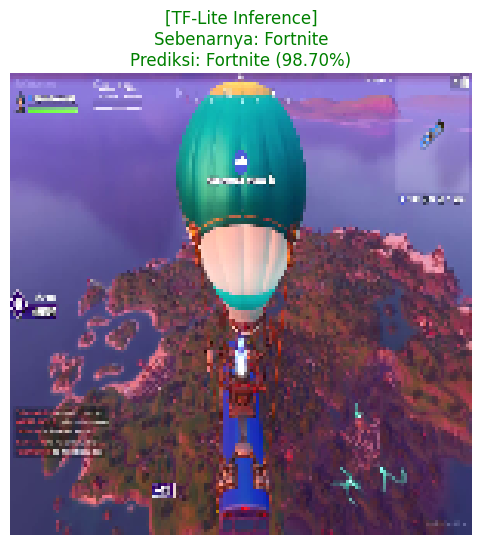

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
import os
import random
import tensorflow as tf

# 1. Definisikan path model TF-Lite hasil ekspor
tflite_model_path = '/content/submission_models/model.tflite'
test_dir = '/content/dataset_split/test'

# Ambil daftar label dari folder test set secara alfabetis
class_names = sorted(os.listdir(test_dir))

# 2. Ambil satu gambar sampel acak dari test set untuk demonstrasi
random_class = random.choice(class_names)
random_class_dir = os.path.join(test_dir, random_class)
random_img_name = random.choice(os.listdir(random_class_dir))
img_path = os.path.join(random_class_dir, random_img_name)

# Load dan visualisasikan gambar
img = image.load_img(img_path, target_size=(150, 150))
x = image.img_to_array(img)
x = np.expand_dims(x, axis=0)
x /= 255.0  # Normalisasi pixel sesuai preprocessing
x = x.astype(np.float32)

# 3. Jalankan Inference menggunakan Interpreter TF-Lite
interpreter = tf.lite.Interpreter(model_path=tflite_model_path)
interpreter.allocate_tensors()

# Dapatkan informasi tensor input dan output
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

# Set tensor input
interpreter.set_tensor(input_details[0]['index'], x)

# Jalankan komputasi
interpreter.invoke()

# Dapatkan hasil prediksi
predictions = interpreter.get_tensor(output_details[0]['index'])
predicted_class_idx = np.argmax(predictions[0])
predicted_class_name = class_names[predicted_class_idx]
confidence = predictions[0][predicted_class_idx] * 100

# 4. Tampilkan Hasil Prediksi menggunakan TF-Lite
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis('off')
plt.title(f"[TF-Lite Inference]\nSebenarnya: {random_class}\nPrediksi: {predicted_class_name} ({confidence:.2f}%)",
          fontsize=12,
          color='green' if random_class == predicted_class_name else 'red')
plt.show()

In [24]:
import os
import shutil
import zipfile

# 1. Tentukan path folder sementara untuk struktur submission
submission_dir = '/content/submission'
if os.path.exists(submission_dir):
    shutil.rmtree(submission_dir)
os.makedirs(submission_dir, exist_ok=True)

# 2. Definisikan sub-folder sesuai kriteria struktur Dicoding
tfjs_dest = os.path.join(submission_dir, 'tfjs_model')
tflite_dest = os.path.join(submission_dir, 'tflite')
saved_model_dest = os.path.join(submission_dir, 'saved_model')

os.makedirs(tfjs_dest, exist_ok=True)
os.makedirs(tflite_dest, exist_ok=True)
os.makedirs(saved_model_dest, exist_ok=True)

# Source paths
src_dir = '/content/submission_models'

# 3. Salin TensorFlow.js model (model.json & *.bin shards)
tfjs_src_dir = os.path.join(src_dir, 'tfjs_model')
if os.path.exists(tfjs_src_dir) and len(os.listdir(tfjs_src_dir)) > 0:
    for file_name in os.listdir(tfjs_src_dir):
        shutil.copy(os.path.join(tfjs_src_dir, file_name), os.path.join(tfjs_dest, file_name))
    print(f"[SUCCESS] Berhasil menyalin {len(os.listdir(tfjs_dest))} file TFJS ke folder submission.")
else:
    print("[WARNING] Folder tfjs_model sumber kosong atau tidak ada!")

# 4. Salin TF-Lite model & buat label.txt
tflite_file_src = os.path.join(src_dir, 'model.tflite')
if os.path.exists(tflite_file_src):
    shutil.copy(tflite_file_src, os.path.join(tflite_dest, 'model.tflite'))

labels = ['Apex Legends', 'Fortnite', 'Forza Horizon', 'Genshin Impact', 'God of War']
with open(os.path.join(tflite_dest, 'label.txt'), 'w') as f:
    f.write('\n'.join(labels))

# 5. Salin SavedModel (termasuk folder variables & assets)
saved_model_src = os.path.join(src_dir, 'saved_model')
if os.path.exists(saved_model_src):
    for item in os.listdir(saved_model_src):
        s_path = os.path.join(saved_model_src, item)
        d_path = os.path.join(saved_model_dest, item)
        if os.path.isdir(s_path):
            shutil.copytree(s_path, d_path)
        else:
            shutil.copy2(s_path, d_path)

# 6. Buat file requirements.txt langsung di dalam folder submission
requirements_content = """tensorflow>=2.21.0
tensorflowjs>=4.22.0
numpy>=1.23.5
matplotlib>=3.7.1
pillow>=9.4.0
requests>=2.31.0
kagglehub>=0.2.0
"""
with open(os.path.join(submission_dir, 'requirements.txt'), 'w') as f:
    f.write(requirements_content.strip())
print("[SUCCESS] Berhasil membuat requirements.txt di folder submission.")

# 7. Buat file README.md
readme_content = """# Proyek Klasifikasi Gambar - Video Game Gameplay

Model ini mengklasifikasikan 5 kelas video game:
1. Apex Legends
2. Fortnite
3. Forza Horizon
4. Genshin Impact
5. God of War
"""
with open(os.path.join(submission_dir, 'README.md'), 'w') as f:
    f.write(readme_content.strip())

# 8. Kompres seluruh struktur direktori submission menjadi format .zip
zip_path = '/content/submission_gameplay_classification.zip'
if os.path.exists(zip_path):
    os.remove(zip_path)

print("\nMengompres folder submission...")
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(submission_dir):
        for file in files:
            file_path = os.path.join(root, file)
            arcname = os.path.relpath(file_path, os.path.dirname(submission_dir))
            zipf.write(file_path, arcname)

print(f"\n[SUCCESS] Berkas ZIP berhasil dibuat di: {zip_path}")

# Tampilkan struktur direktori akhir dari zip untuk verifikasi
print("\nStruktur Direktori ZIP Submission:")
with zipfile.ZipFile(zip_path, 'r') as zf:
    zf.printdir()

[SUCCESS] Berhasil menyalin 4 file TFJS ke folder submission.
[SUCCESS] Berhasil membuat requirements.txt di folder submission.

Mengompres folder submission...

[SUCCESS] Berkas ZIP berhasil dibuat di: /content/submission_gameplay_classification.zip

Struktur Direktori ZIP Submission:
File Name                                             Modified             Size
submission/README.md                           2026-11-02 16:47:22          176
submission/requirements.txt                    2026-11-02 16:47:22          119
submission/saved_model/saved_model.pb          2026-11-02 16:46:16      1669289
submission/saved_model/fingerprint.pb          2026-11-02 16:46:16           96
submission/saved_model/variables/variables.data-00000-of-00001 2026-11-02 16:46:16     20756734
submission/saved_model/variables/variables.index 2026-11-02 16:46:16        29770
submission/tfjs_model/group1-shard2of3.bin     2026-11-02 16:47:22      4194304
submission/tfjs_model/model.json               2026-11-